# Catálogo JPL: ¿funciona el modelo con asteroides recién descubiertos?

**Introducción a la Inteligencia Artificial** · 6.º semestre · complemento de `pipeline_asteroides.ipynb`

**Integrantes:** Dylan Alexander Mejia Ceballos · Luis Miguel Brito Rincon · Gabriel Alejandro Giraldo Ayerbe · Juan Pablo Muñoz Corchos · Juan Pablo Agudelo · Evelyn Gómez Aristizabal

En el notebook principal vimos que, si el modelo tiene el MOID, solo copia la regla de la NASA. Aquí probamos un uso más realista: **entrenar con los asteroides descubiertos hasta 2023 y evaluar con los descubiertos de 2024 en adelante**, como si el modelo ya estuviera funcionando y le llegaran objetos recién descubiertos. Muchos de ellos tienen pocas observaciones y una órbita todavía incierta.

Los datos son el catálogo de objetos cercanos a la Tierra (NEOs) de la *Small-Body Database* (SBDB) del JPL de la NASA, descargado de su API oficial, con una fila por asteroide.

| | `nasa.csv` (notebook principal) | Catálogo JPL (este notebook) |
| :--- | :--- | :--- |
| Asteroides | 3,692 (4,687 filas) | ~42,900 |
| Filas repetidas por asteroide | Sí, por eso la partición es agrupada | No, una fila por asteroide |
| Actualidad | Versión publicada en Kaggle | Descargado de la API oficial |
| Calidad de la órbita | `Orbit Uncertainity` | `condition_code`, `data_arc`, `n_obs_used` |
| Fecha de descubrimiento | No | `first_obs`, que permite partir por fecha |

## Contenido

0. [Configuración del entorno](#j0)
1. [Obtención de los datos](#j1)
2. [Cómo cambia el catálogo con el tiempo](#j2) · *Analyze*
3. [Partición temporal, variables y escenarios](#j3) · *Design*
4. [Modelos](#j4) · *Configure & Build*
   - [4.1 Comparación de modelos](#j4-1)
   - [4.2 ¿Sirve entrenar solo con años recientes?](#j4-2)
   - [4.3 ¿Se puede calcular el MOID desde la órbita?](#j4-3)
5. [Evaluación con asteroides recién descubiertos](#j5) · *Configure & Build*
   - [5.1 Umbral F2 en Validación y tasa de alertas](#j5-1)
   - [5.2 Pruebas de sobreajuste](#j5-2)
   - [5.3 Evaluación en Test](#j5-3)
   - [5.4 Intervalos de confianza en Test](#j5-4)
6. [Desempeño según la calidad de la órbita y en los asteroides grandes](#j6)
7. [Cambio entre el entrenamiento y los recién descubiertos](#j7) · *Operate & Optimize*
8. [Resultados y conclusiones](#j8)
   - [8.1 Cifras clave](#j8-1)
   - [8.2 Datos para la presentación](#j8-2)
   - [8.3 Conclusiones](#j8-3)

### Dónde está cada tema

| Tema | Sección |
| :--- | :--- |
| Partición temporal (Train y Validación hasta 2023, Test 2024+) | [3](#j3) |
| Comparación de modelos con validación cruzada | [4.1](#j4-1) |
| Entrenar solo con años recientes | [4.2](#j4-2) |
| Cálculo del MOID desde la órbita y variables de geometría orbital | [4.3](#j4-3) |
| Umbral de decisión con $F_2$ y tasa de alertas | [5.1](#j5-1), [5.3](#j5-3) |
| Sobreajuste: curva de aprendizaje e importancia por permutación | [5.2](#j5-2) |
| Intervalos de confianza (bootstrap) | [5.4](#j5-4) |
| Calidad de la órbita, asteroides grandes y por qué baja la precisión | [6](#j6) |
| Cambio en el tamaño de los recién descubiertos | [2](#j2), [7](#j7) |
| Conclusiones | [8.3](#j8-3) |

<a id="j0"></a>
## 0. Configuración del entorno

Librerías, semilla y las mismas funciones auxiliares del notebook principal: el pipeline con imputación, el resumen de la validación cruzada, el umbral F2 y las métricas con un umbral dado. Cada proceso de entrenamiento en paralelo usa 2 hilos (`OMP_NUM_THREADS`) para que los modelos no compitan por los núcleos.

In [1]:
# 0. Configuración del entorno y funciones auxiliares
import os

# Evita el error de joblib/loky con `wmic` en Windows 11 (igual que en el notebook principal)
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(max(1, (os.cpu_count() or 2) // 2)))
# Muchos modelos se entrenan en paralelo; con 2 hilos de OpenMP por proceso no se pisan entre ellos
os.environ.setdefault('OMP_NUM_THREADS', '2')

import json
import urllib.parse
import urllib.request
import warnings
from datetime import datetime
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.base import BaseEstimator, clone
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score, fbeta_score, make_scorer, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier, RandomForestClassifier

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.max_colwidth', None)

SEED = 42
TARGET = 'peligroso'
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)

SCORING: dict[str, Any] = {
    'pr_auc': 'average_precision',
    'f2': make_scorer(fbeta_score, beta=2),
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'precision': make_scorer(precision_score, zero_division=0)
}


def hacer_pipeline(clf: BaseEstimator, escalador: Any = None) -> Pipeline:
    """Pipeline con imputación por mediana, escalado opcional y clasificador."""
    pasos: list[tuple[str, Any]] = [('imputer', SimpleImputer(strategy='median'))]
    if escalador is not None:
        pasos.append(('scaler', clone(escalador)))
    pasos.append(('clf', clf))
    return Pipeline(pasos)


def resumir_cv(res: dict[str, np.ndarray], metricas: list[str]) -> dict[str, float]:
    """Medias y desviaciones estándar de la salida de cross_validate."""
    out: dict[str, float] = {}
    for m in metricas:
        out[m] = float(np.mean(res[f'test_{m}']))
        out[f'{m}_std'] = float(np.std(res[f'test_{m}']))
    return out


def umbral_f2(y_true: np.ndarray, probs: np.ndarray) -> tuple[float, float]:
    """Umbral que maximiza F2 sobre la curva Precision-Recall, y el F2 alcanzado."""
    precs, recs, thrs = precision_recall_curve(y_true, probs)
    p, r = precs[:-1], recs[:-1]
    f2 = np.where((4 * p + r) > 0, 5 * p * r / (4 * p + r + 1e-12), 0)
    i = int(np.argmax(f2))
    return float(thrs[i]), float(f2[i])


def metricas_binarias(y_true: np.ndarray, probs: np.ndarray, umbral: float) -> dict[str, float]:
    """Métricas con un umbral dado. Las que no están definidas (p. ej. sin positivos) se devuelven como NaN."""
    y_true = np.asarray(y_true)
    pred = (np.asarray(probs) >= umbral).astype(int)
    dos_clases = len(np.unique(y_true)) == 2
    positivos = int(y_true.sum())
    return {
        'pr_auc': average_precision_score(y_true, probs) if dos_clases else np.nan,
        'roc_auc': roc_auc_score(y_true, probs) if dos_clases else np.nan,
        'f2': fbeta_score(y_true, pred, beta=2, zero_division=0) if positivos else np.nan,
        'f1': f1_score(y_true, pred, zero_division=0) if positivos else np.nan,
        'recall': recall_score(y_true, pred, zero_division=0) if positivos else np.nan,
        'precision': precision_score(y_true, pred, zero_division=0) if pred.sum() else np.nan,
        'accuracy': accuracy_score(y_true, pred),
        'positivos': positivos,
        'falsos_negativos': int(((pred == 0) & (y_true == 1)).sum()),
        'falsos_positivos': int(((pred == 1) & (y_true == 0)).sum()),
        'tasa_alertas': float(pred.mean())
    }


print(f'scikit-learn {sklearn.__version__} | pandas {pd.__version__}')

scikit-learn 1.6.1 | pandas 2.2.3


<a id="j1"></a>
## 1. Obtención de los datos (SBDB Query API)

Hacemos una sola consulta a `https://ssd-api.jpl.nasa.gov/sbdb_query.api` con `sb-group=neo` (todos los objetos cercanos a la Tierra) y guardamos el resultado en `sbdb_neos.csv`. Las siguientes ejecuciones leen ese archivo, así que el análisis se puede repetir sin internet y da los mismos resultados. Para actualizarlo basta con borrar el CSV o llamar `descargar_catalogo(..., forzar=True)`.

| Campo | Significado |
| :--- | :--- |
| `pha` | Etiqueta oficial: *Potentially Hazardous Asteroid* (Y/N) |
| `H` | Magnitud absoluta (menor = más grande) |
| `e`, `a`, `q`, `ad`, `i`, `om`, `w` | Excentricidad, semieje mayor, perihelio, afelio (UA), inclinación, nodo ascendente y argumento del perihelio (°) |
| `per`, `n`, `t_jup` | Período (días), movimiento medio (°/día) e invariante de Tisserand respecto a Júpiter |
| `moid` | Distancia mínima entre la órbita del asteroide y la de la Tierra (UA) |
| `condition_code` | Calidad de la órbita: 0 = muy bien determinada, 9 = muy incierta |
| `data_arc`, `n_obs_used` | Días entre la primera y la última observación, y número de observaciones usadas |
| `first_obs` | Fecha de la primera observación (más o menos, la del descubrimiento) |

In [2]:
# 1. Descarga (o lectura del CSV guardado) y limpieza
RUTA_CATALOGO = Path('sbdb_neos.csv')
URL_API = 'https://ssd-api.jpl.nasa.gov/sbdb_query.api'
CAMPOS = ['spkid', 'pdes', 'full_name', 'pha', 'H', 'diameter', 'albedo', 'e', 'a', 'q', 'i', 'om', 'w', 'ma',
          'ad', 'per', 'n', 'moid', 't_jup', 'condition_code', 'data_arc', 'n_obs_used', 'first_obs', 'last_obs', 'class']
NUMERICAS = ['H', 'diameter', 'albedo', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'per', 'n', 'moid', 't_jup',
             'condition_code', 'data_arc', 'n_obs_used']


def descargar_catalogo(ruta: Path, forzar: bool = False) -> pd.DataFrame:
    """Descarga el catálogo de NEOs de la SBDB en una sola consulta y lo guarda como CSV; si ya existe, lo reutiliza."""
    if ruta.exists() and not forzar:
        return pd.read_csv(ruta, dtype={'spkid': str, 'pdes': str})
    url = URL_API + '?' + urllib.parse.urlencode({'fields': ','.join(CAMPOS), 'sb-group': 'neo'})
    with urllib.request.urlopen(url, timeout=180) as resp:
        payload = json.load(resp)
    cat = pd.DataFrame(payload['data'], columns=payload['fields'])
    cat.to_csv(ruta, index=False)
    return pd.read_csv(ruta, dtype={'spkid': str, 'pdes': str})


bruto = descargar_catalogo(RUTA_CATALOGO)
FECHA_CATALOGO = datetime.fromtimestamp(RUTA_CATALOGO.stat().st_mtime).date().isoformat()
print(f'Catálogo: {len(bruto):,} NEOs | descargado el {FECHA_CATALOGO} | {RUTA_CATALOGO.stat().st_size / 1e6:.1f} MB')

cat = bruto.copy()
cat[NUMERICAS] = cat[NUMERICAS].apply(pd.to_numeric, errors='coerce')
cat['anio'] = pd.to_datetime(cat['first_obs'], errors='coerce').dt.year
assert cat['pdes'].is_unique, 'Hay asteroides repetidos'

sin_etiqueta = cat['pha'].isna() | cat['anio'].isna()
print(f'Descartados {sin_etiqueta.sum()} objetos sin etiqueta PHA o sin fecha de descubrimiento '
      f'(sin H, la NASA no puede clasificarlos).')
cat = cat[~sin_etiqueta].copy()
cat['anio'] = cat['anio'].astype(int)
cat[TARGET] = (cat['pha'] == 'Y').astype(int)

print(f'Asteroides válidos: {len(cat):,} | peligrosos (PHA): {cat[TARGET].sum():,} ({cat[TARGET].mean():.1%})')
print('Valores faltantes por variable:', (cat[NUMERICAS].isna().mean() * 100).round(1).loc[lambda s: s > 0].to_dict())

# La etiqueta sigue siendo la regla CNEOS, igual que en nasa.csv
regla = ((cat['moid'] <= 0.05) & (cat['H'] <= 22.0)).astype(int)
ACUERDO_REGLA = float((regla == cat[TARGET]).mean())
print(f'Coincidencia de la regla (MOID <= 0.05 y H <= 22) con la etiqueta oficial: {ACUERDO_REGLA:.2%}')
display(pd.crosstab(regla.rename('Regla'), cat[TARGET].rename('PHA oficial')))

Catálogo: 42,926 NEOs | descargado el 2026-10-11 | 6.7 MB
Descartados 344 objetos sin etiqueta PHA o sin fecha de descubrimiento (sin H, la NASA no puede clasificarlos).
Asteroides válidos: 42,582 | peligrosos (PHA): 2,550 (6.0%)
Valores faltantes por variable: {'diameter': 97.1, 'albedo': 97.2, 'data_arc': 1.0}
Coincidencia de la regla (MOID <= 0.05 y H <= 22) con la etiqueta oficial: 99.88%


PHA oficial,0,1
Regla,,
0,40015,33
1,17,2517


<a id="j2"></a>
## 2. Cómo cambia el catálogo con el tiempo (Analyze)

Lo primero es ver qué tipo de asteroides se descubren hoy. Los telescopios son cada vez más sensibles y detectan objetos más pequeños (con H mayor). Como la regla exige $H \le 22$, esperamos que entre los recién descubiertos haya menos peligrosos que en el histórico. Ese cambio en los datos (*drift*) es algo que el modelo tiene que aguantar.

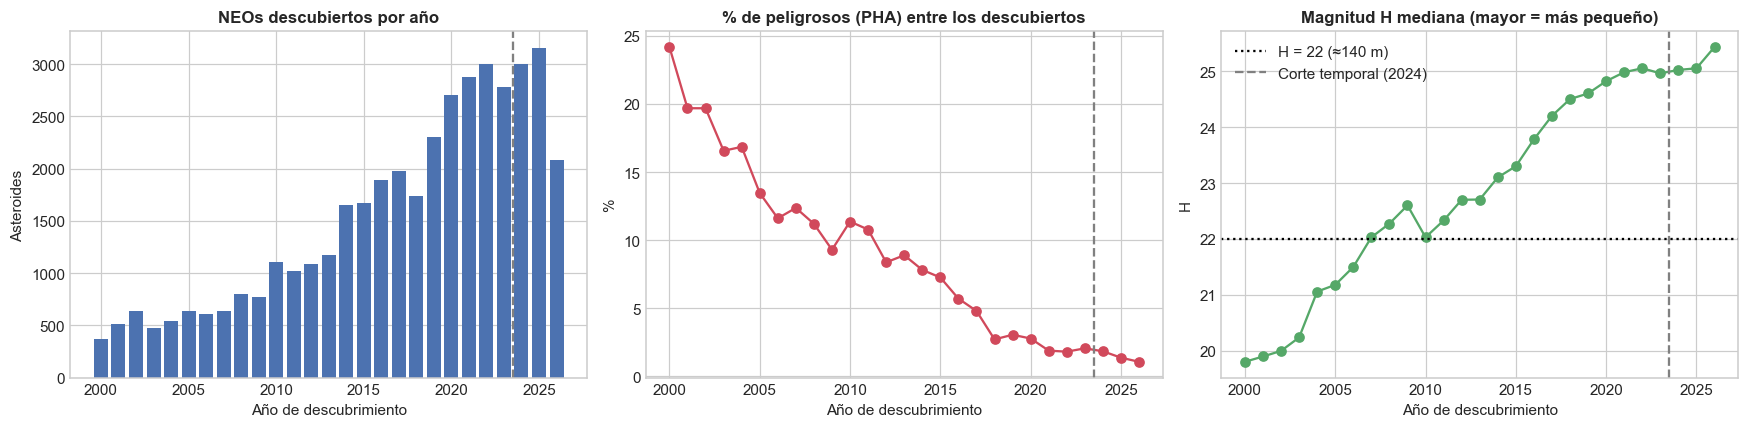

Nota: 2026 es un año incompleto (catálogo descargado el 2026-10-11).


,asteroides,pct_pha,pct_H_menor_22,H_mediana,arco_mediano_dias,obs_medianas
periodo,,,,,,
Histórico (< 2024),34340,0.071,0.319,23.745,28.0,46.0
Recientes (2024-2026),8242,0.015,0.096,25.130,10.0,34.0


Distribución de la calidad de órbita por periodo (% de asteroides):


calidad_orbita,Buena (U 0-3),Media (U 4-6),Incierta (U 7-9)
periodo,,,
Histórico (< 2024),32.9,18.8,48.2
Recientes (2024-2026),1.9,29.5,68.6


In [3]:
# 2. Evolución de los descubrimientos por año
ANIO_CORTE = 2024   # Test: descubiertos de 2024 en adelante
ANIO_ACTUAL = int(cat['anio'].max())

por_anio = cat.groupby('anio').agg(descubiertos=(TARGET, 'size'), pct_pha=(TARGET, 'mean'), H_mediana=('H', 'median'),
                                   pct_grandes=('H', lambda h: (h <= 22).mean()))
sub = por_anio.loc[2000:]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(sub.index, sub['descubiertos'], color='#4C72B0')
axes[0].set_title('NEOs descubiertos por año')
axes[0].set_ylabel('Asteroides')
axes[1].plot(sub.index, 100 * sub['pct_pha'], marker='o', color='#D1495B')
axes[1].set_title('% de peligrosos (PHA) entre los descubiertos')
axes[1].set_ylabel('%')
axes[2].plot(sub.index, sub['H_mediana'], marker='o', color='#55A868')
axes[2].axhline(22, color='black', ls=':', label='H = 22 (≈140 m)')
axes[2].set_title('Magnitud H mediana (mayor = más pequeño)')
axes[2].set_ylabel('H')
for ax in axes:
    ax.axvline(ANIO_CORTE - 0.5, color='gray', ls='--', label=f'Corte temporal ({ANIO_CORTE})')
    ax.set_xlabel('Año de descubrimiento')
axes[2].legend()
plt.tight_layout()
plt.show()
print(f'Nota: {ANIO_ACTUAL} es un año incompleto (catálogo descargado el {FECHA_CATALOGO}).')

# Comparación histórico vs recientes
cat['periodo'] = np.where(cat['anio'] < ANIO_CORTE, f'Histórico (< {ANIO_CORTE})', f'Recientes ({ANIO_CORTE}-{ANIO_ACTUAL})')
cat['calidad_orbita'] = pd.cut(cat['condition_code'], [-1, 3, 6, 9],
                               labels=['Buena (U 0-3)', 'Media (U 4-6)', 'Incierta (U 7-9)'])
resumen_periodo = cat.groupby('periodo').agg(
    asteroides=(TARGET, 'size'), pct_pha=(TARGET, 'mean'), pct_H_menor_22=('H', lambda h: (h <= 22).mean()),
    H_mediana=('H', 'median'), arco_mediano_dias=('data_arc', 'median'), obs_medianas=('n_obs_used', 'median'))
display(resumen_periodo.round(3))
print('Distribución de la calidad de órbita por periodo (% de asteroides):')
display((pd.crosstab(cat['periodo'], cat['calidad_orbita'], normalize='index') * 100).round(1))

<a id="j3"></a>
## 3. Partición temporal, variables y escenarios (Design)

**Partición por fecha de descubrimiento (simula el uso real):**

| Conjunto | Asteroides | Para qué se usa |
| :--- | :--- | :--- |
| Train (80%) | Descubiertos hasta 2023, al azar y estratificado | Comparación de modelos y entrenamiento |
| Validación (20%) | Descubiertos hasta 2023, al azar y estratificado | Solo para escoger el umbral F2 |
| Test | Todos los descubiertos de 2024 en adelante | Evaluación final, una sola vez |

El modelo nunca ve los asteroides de Test y estos llegaron después, como pasaría en la práctica.

Aquí hay una fila por asteroide, así que no existe la fuga por agrupamiento del notebook principal y basta con `StratifiedKFold`.

**Variables que no usamos:**

- `diameter` y `albedo`: faltan en ~97% de los asteroides (solo se conocen para los que se han estudiado a fondo). El tamaño ya está en `H`.
- `ma` (anomalía media): dice en qué punto de su órbita va el asteroide en una fecha cualquiera; no cambia el riesgo.
- `condition_code`, `data_arc`, `n_obs_used` y las fechas: dicen cuánto se ha observado el asteroide, no cómo es. Las usamos para analizar los resultados ([sección 6](#j6)), no para predecir, para que el modelo no aprenda atajos como "objeto viejo y muy observado".

**Escenarios** (los mismos del notebook principal):

- **A:** todas las variables, incluido `moid`. El modelo puede copiar la regla.
- **B:** sin `moid`. El modelo tiene que deducir la cercanía a partir de la órbita. Es el escenario que más nos interesa.
- **C:** sin `moid` ni `H`. Sin ninguna de las dos condiciones de la definición.

In [4]:
# 3. Variables, escenarios y partición temporal
FEATURES = ['H', 'e', 'a', 'q', 'ad', 'i', 'om', 'w', 'per', 'n', 't_jup', 'moid']
ESCENARIOS: dict[str, list[str]] = {
    'A_completo': [],
    'B_sin_MOID': ['moid'],
    'C_sin_definicion': ['moid', 'H']
}
ESCENARIO_FOCO = 'B_sin_MOID'


def columnas_escenario(nombre: str) -> list[str]:
    """Variables predictoras disponibles en un escenario de fuga."""
    return [c for c in FEATURES if c not in ESCENARIOS[nombre]]


historico = cat[cat['anio'] < ANIO_CORTE]
test = cat[cat['anio'] >= ANIO_CORTE].copy()
train, val = train_test_split(historico, test_size=0.2, stratify=historico[TARGET], random_state=SEED)
y_train, y_val, y_test = train[TARGET].to_numpy(), val[TARGET].to_numpy(), test[TARGET].to_numpy()

assert not (set(train['pdes']) & set(test['pdes'])) and not (set(val['pdes']) & set(test['pdes']))
print('Partición temporal:')
for nombre, d in [('Train', train), ('Validación', val), (f'Test ({ANIO_CORTE}-{ANIO_ACTUAL})', test)]:
    print(f'{nombre:18s}: {len(d):6,} asteroides | {d[TARGET].sum():5,} PHA ({d[TARGET].mean():5.2%}) | '
          f'H mediana {d["H"].median():.1f} | órbita incierta (U 7-9): {(d["condition_code"] >= 7).mean():.0%}')
for esc in ESCENARIOS:
    print(f'  · {esc:17s}: {columnas_escenario(esc)}')

Partición temporal:
Train             : 27,472 asteroides | 1,944 PHA (7.08%) | H mediana 23.7 | órbita incierta (U 7-9): 48%
Validación        :  6,868 asteroides |   486 PHA (7.08%) | H mediana 23.8 | órbita incierta (U 7-9): 48%
Test (2024-2026)  :  8,242 asteroides |   120 PHA (1.46%) | H mediana 25.1 | órbita incierta (U 7-9): 69%
  · A_completo       : ['H', 'e', 'a', 'q', 'ad', 'i', 'om', 'w', 'per', 'n', 't_jup', 'moid']
  · B_sin_MOID       : ['H', 'e', 'a', 'q', 'ad', 'i', 'om', 'w', 'per', 'n', 't_jup']
  · C_sin_definicion : ['e', 'a', 'q', 'ad', 'i', 'om', 'w', 'per', 'n', 't_jup']


<a id="j4"></a>
## 4. Modelos (Configure & Build)

<a id="j4-1"></a>
### 4.1 Comparación de modelos

Validación cruzada estratificada de 5 folds sobre Train. Probamos los modelos que mejor funcionaron en el notebook principal y dos de referencia; SVM, k-NN y MLP los dejamos por fuera porque son lentos con ~30,000 filas y allá no se destacaron.

- `Baseline` (clase mayoritaria) y `Regresión logística` (referencia lineal).
- `Random Forest`, `Bagging` (con la configuración que ganó en el notebook principal: 200 árboles, `max_features=0.7`) y `Gradient Boosting`.

Ordenamos por PR-AUC, que es la métrica adecuada porque aquí solo ~6% son peligrosos, y si hay empate, por F2. Cuando la diferencia entre los dos primeros es menor que su desviación estándar, la tomamos como no concluyente. También guardamos el PR-AUC sobre los datos de entrenamiento de cada fold para las pruebas de sobreajuste de [5.2](#j5-2).

In [5]:
# 4.1 Comparación de modelos por escenario (CV estratificada de 5 folds sobre Train)
MODELOS: dict[str, Pipeline] = {
    'Baseline (Mayoritaria)': hacer_pipeline(DummyClassifier(strategy='most_frequent')),
    'Regresión Logística': hacer_pipeline(LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEED),
                                          StandardScaler()),
    'Random Forest': hacer_pipeline(RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEED, n_jobs=1)),
    'Bagging': hacer_pipeline(BaggingClassifier(n_estimators=200, max_features=0.7, random_state=SEED, n_jobs=1)),
    'Gradient Boosting': hacer_pipeline(GradientBoostingClassifier(random_state=SEED))
}
METRICAS = list(SCORING)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

filas = []
for esc in ESCENARIOS:
    X_tr = train[columnas_escenario(esc)]
    for nombre, modelo in MODELOS.items():
        res = cross_validate(clone(modelo), X_tr, y_train, cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=True)
        filas.append({'Escenario': esc, 'Modelo': nombre, **resumir_cv(res, METRICAS), 'train_pr_auc': float(np.mean(res['train_pr_auc']))})
df_bench = pd.DataFrame(filas)

rankings: dict[str, pd.DataFrame] = {
    esc: (df_bench[df_bench['Escenario'] == esc].sort_values(['pr_auc', 'f2'], ascending=False).reset_index(drop=True))
    for esc in ESCENARIOS
}
for esc, r in rankings.items():
    tabla = r[['Modelo']].copy()
    for m in METRICAS:
        tabla[m] = r[m].map('{:.4f}'.format) + ' ± ' + r[f'{m}_std'].map('{:.4f}'.format)
    print(f'\nRanking CV 5-fold: {esc}')
    display(tabla)
    primero, segundo = r.iloc[0], r.iloc[1]
    dif = primero['pr_auc'] - segundo['pr_auc']
    veredicto = 'no concluyente' if dif < max(primero['pr_auc_std'], segundo['pr_auc_std']) else 'clara'
    print(f"Ganador: {primero['Modelo']} | diferencia con {segundo['Modelo']}: {dif:.4f} de PR-AUC "
          f"(desviación {primero['pr_auc_std']:.4f}) -> diferencia {veredicto}")

pivot_pr = df_bench.pivot(index='Modelo', columns='Escenario', values='pr_auc')[list(ESCENARIOS)]
print('PR-AUC por escenario (CV):')
display(pivot_pr.sort_values('B_sin_MOID', ascending=False).round(4))

ganador_b = rankings[ESCENARIO_FOCO].loc[rankings[ESCENARIO_FOCO]['Modelo'] != 'Baseline (Mayoritaria)', 'Modelo'].iloc[0]
cols_b = columnas_escenario(ESCENARIO_FOCO)


Ranking CV 5-fold: A_completo


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision
0,Random Forest,0.9961 ± 0.0022,0.9905 ± 0.0038,0.9902 ± 0.0042,0.9989 ± 0.0008,0.9907 ± 0.0045,0.9898 ± 0.0075
1,Gradient Boosting,0.9960 ± 0.0054,0.9886 ± 0.0035,0.9899 ± 0.0025,0.9998 ± 0.0001,0.9877 ± 0.0044,0.9923 ± 0.0032
2,Bagging,0.9944 ± 0.0040,0.9819 ± 0.0051,0.9865 ± 0.0034,0.9991 ± 0.0003,0.9789 ± 0.0064,0.9943 ± 0.0035
3,Regresión Logística,0.8381 ± 0.0247,0.8410 ± 0.0087,0.7048 ± 0.0091,0.9879 ± 0.0018,0.9655 ± 0.0104,0.5550 ± 0.0098
4,Baseline (Mayoritaria),0.0708 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000


Ganador: Random Forest | diferencia con Gradient Boosting: 0.0000 de PR-AUC (desviación 0.0022) -> diferencia no concluyente

Ranking CV 5-fold: B_sin_MOID


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision
0,Bagging,0.8091 ± 0.0125,0.2594 ± 0.0051,0.3542 ± 0.0067,0.9833 ± 0.0015,0.2202 ± 0.0044,0.9049 ± 0.0173
1,Gradient Boosting,0.7562 ± 0.0194,0.4871 ± 0.0205,0.5690 ± 0.0199,0.9765 ± 0.0018,0.4445 ± 0.0208,0.7920 ± 0.0297
2,Random Forest,0.7437 ± 0.0091,0.4888 ± 0.0205,0.5664 ± 0.0146,0.9768 ± 0.0014,0.4480 ± 0.0228,0.7720 ± 0.0181
3,Regresión Logística,0.2793 ± 0.0150,0.6042 ± 0.0066,0.4081 ± 0.0056,0.8986 ± 0.0045,0.8889 ± 0.0113,0.2649 ± 0.0045
4,Baseline (Mayoritaria),0.0708 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000


Ganador: Bagging | diferencia con Gradient Boosting: 0.0529 de PR-AUC (desviación 0.0125) -> diferencia clara

Ranking CV 5-fold: C_sin_definicion


,Modelo,pr_auc,f2,f1,roc_auc,recall,precision
0,Gradient Boosting,0.1984 ± 0.0084,0.0045 ± 0.0043,0.0071 ± 0.0068,0.7904 ± 0.0073,0.0036 ± 0.0035,0.2300 ± 0.1392
1,Bagging,0.1978 ± 0.0083,0.0096 ± 0.0053,0.0151 ± 0.0084,0.7861 ± 0.0074,0.0077 ± 0.0043,0.3177 ± 0.1990
2,Random Forest,0.1834 ± 0.0086,0.0083 ± 0.0048,0.0130 ± 0.0075,0.7811 ± 0.0075,0.0067 ± 0.0038,0.2525 ± 0.1539
3,Regresión Logística,0.1519 ± 0.0056,0.3918 ± 0.0126,0.2481 ± 0.0063,0.7573 ± 0.0070,0.6389 ± 0.0297,0.1539 ± 0.0035
4,Baseline (Mayoritaria),0.0708 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000


Ganador: Gradient Boosting | diferencia con Bagging: 0.0005 de PR-AUC (desviación 0.0084) -> diferencia no concluyente
PR-AUC por escenario (CV):


Escenario,A_completo,B_sin_MOID,C_sin_definicion
Modelo,,,
Bagging,0.9944,0.8091,0.1978
Gradient Boosting,0.9960,0.7562,0.1984
Random Forest,0.9961,0.7437,0.1834
Regresión Logística,0.8381,0.2793,0.1519
Baseline (Mayoritaria),0.0708,0.0708,0.0708


<a id="j4-2"></a>
### 4.2 ¿Sirve entrenar solo con años recientes?

Los asteroides descubiertos hace décadas son, en promedio, más grandes que los de hoy (sección [2](#j2)). Entrenar solo con los descubiertos en años recientes podría parecerse más a los recién descubiertos, pero deja menos datos.

Lo probamos aparte, como análisis: entrenamos el ganador del escenario B con cuatro ventanas de años (todos los descubiertos hasta 2020, o solo los descubiertos desde 2000, desde 2010 o desde 2015) y lo evaluamos con todos los descubiertos entre 2021 y 2023, que hacen de "recién descubiertos" para esas ventanas. Para cada ventana reportamos cuántos asteroides tiene, su H mediana, y el PR-AUC, la precisión y el recall con su umbral F2. Test no se usa aquí, y el modelo de la sección 5 se entrena con todo Train.

In [6]:
# 4.2 ¿Sirve entrenar solo con años recientes? (análisis: se evalúa con los descubiertos de 2021-2023, Test no se usa)
ANIO_RECIENTES = 2021
pasado = cat[cat['anio'] < ANIO_RECIENTES]
recientes_21_23 = cat[(cat['anio'] >= ANIO_RECIENTES) & (cat['anio'] < ANIO_CORTE)]
y_rec = recientes_21_23[TARGET].to_numpy()
VENTANAS = {f'Todos (hasta {ANIO_RECIENTES - 1})': int(pasado['anio'].min()), 'Desde 2000': 2000, 'Desde 2010': 2010, 'Desde 2015': 2015}

filas_v = []
for nombre_v, desde in VENTANAS.items():
    sub = pasado[pasado['anio'] >= desde]
    m = clone(MODELOS[ganador_b]).fit(sub[cols_b], sub[TARGET])
    p_rec = m.predict_proba(recientes_21_23[cols_b])[:, 1]
    u, _ = umbral_f2(y_rec, p_rec)
    mv = metricas_binarias(y_rec, p_rec, u)
    filas_v.append({'Ventana': nombre_v, 'Desde': desde, 'Asteroides': len(sub), '% PHA': sub[TARGET].mean(),
                    'H mediana': sub['H'].median(), 'PR-AUC (2021-2023)': mv['pr_auc'],
                    'Precision': mv['precision'], 'Recall': mv['recall'], 'Umbral F2': u})
df_ventanas = pd.DataFrame(filas_v).set_index('Ventana')
display(df_ventanas.round(4))

MEJOR_VENTANA = (df_ventanas.assign(_pr=df_ventanas['PR-AUC (2021-2023)'].round(3))
                 .sort_values(['_pr', 'Asteroides'], ascending=[False, False]).index[0])
print(f'Descubiertos en {ANIO_RECIENTES}-{ANIO_CORTE - 1}: {len(recientes_21_23):,} asteroides, {y_rec.mean():.2%} PHA, '
      f'H mediana {recientes_21_23["H"].median():.1f}')
print(f'Ventana con mayor PR-AUC (si empatan a 3 decimales, la de más datos): {MEJOR_VENTANA}')

,Desde,Asteroides,% PHA,H mediana,PR-AUC (2021-2023),Precision,Recall,Umbral F2
Ventana,,,,,,,,
Todos (hasta 2020),1893,25683,0.0882,23.10,0.8589,0.6595,0.9273,0.290
Desde 2000,2000,24338,0.0805,23.30,0.8414,0.6711,0.9273,0.295
Desde 2010,2010,18330,0.0587,23.88,0.8323,0.6579,0.9091,0.280
Desde 2015,2015,12290,0.0420,24.30,0.7975,0.5048,0.9515,0.190


Descubiertos en 2021-2023: 8,657 asteroides, 1.91% PHA, H mediana 25.0
Ventana con mayor PR-AUC (si empatan a 3 decimales, la de más datos): Todos (hasta 2020)


<a id="j4-3"></a>
### 4.3 ¿Se puede calcular el MOID desde la órbita?

El escenario B le quita al modelo la columna `moid`, pero el MOID no es un dato independiente: es una distancia geométrica que sale de la órbita. Lo comprobamos de dos formas, igual que en el notebook principal:

1. **Cálculo directo.** Recorremos la órbita de cada asteroide en 720 puntos (`a`, `e`, `i`, `w`) y medimos la distancia mínima a un círculo de 1 UA en el plano de la Tierra. Comparamos ese MOID calculado con el del JPL.
2. **Variables de geometría orbital.** Con `a`, `e`, `w`, `q` y `ad` calculamos la distancia al Sol en los dos nodos (donde la órbita cruza el plano de la Tierra), la del nodo más cercano a 1 UA, si la órbita cruza 1 UA y qué tan lejos queda de 1 UA. Con validación cruzada comparamos el modelo del escenario B con y sin estas seis variables, y con el escenario A.

Esta sección es un análisis: ni el MOID calculado ni las seis variables entran al modelo del escenario B que se evalúa en la sección 5.

In [7]:
# 4.3 ¿Se puede calcular el MOID desde la órbita? (análisis: nada de esto entra al modelo evaluado)
def moid_desde_orbita(d: pd.DataFrame, n: int = 720) -> np.ndarray:
    """Distancia mínima entre la órbita (en n puntos) y un círculo de 1 UA en la eclíptica."""
    a, e, i, w = (d[c].to_numpy(float)[:, None] for c in ['a', 'e', 'i', 'w'])
    nu = np.linspace(0, 2 * np.pi, n, endpoint=False)[None, :]       # anomalía verdadera
    r = a * (1 - e ** 2) / (1 + e * np.cos(nu))
    u, inc = nu + np.radians(w), np.radians(i)
    x, y_orb, z = r * np.cos(u), r * np.sin(u) * np.cos(inc), r * np.sin(u) * np.sin(inc)
    return np.sqrt((np.sqrt(x ** 2 + y_orb ** 2) - 1) ** 2 + z ** 2).min(axis=1)


def geometria_orbital(d: pd.DataFrame) -> pd.DataFrame:
    """Seis variables de la geometría de la órbita frente a la de la Tierra (un círculo de 1 UA en la eclíptica)."""
    a, e, q, Q = d['a'], d['e'], d['q'], d['ad']
    p = a * (1 - e ** 2)                                        # semilado recto
    cos_w = np.cos(np.radians(d['w']))
    r_asc, r_desc = p / (1 + e * cos_w), p / (1 - e * cos_w)    # distancia al Sol en cada nodo
    cruza = ((q <= 1) & (Q >= 1)).astype(float)
    return pd.DataFrame({
        'Dist. nodo asc. (UA)': r_asc,
        'Dist. nodo desc. (UA)': r_desc,
        'Nodo más cercano a 1 UA': np.minimum((r_asc - 1).abs(), (r_desc - 1).abs()),
        'Cruza 1 UA': cruza,
        'Dist. q-Q a 1 UA': np.where(cruza == 1, 0.0, np.minimum((q - 1).abs(), (Q - 1).abs())),
        'q - 1 UA': q - 1,
    }, index=d.index)


con_moid = cat[cat['moid'].notna()]
moid_calc = moid_desde_orbita(con_moid)
moid_real = con_moid['moid'].to_numpy()
CORR_MOID = float(np.corrcoef(moid_calc, moid_real)[0, 1])
ACUERDO_MOID = float(((moid_calc <= 0.05) == (moid_real <= 0.05)).mean())
print(f'MOID calculado vs MOID del JPL ({len(con_moid):,} asteroides): correlación {CORR_MOID:.4f} | '
      f'error mediano {np.median(np.abs(moid_calc - moid_real)):.4f} UA | mismo lado de 0.05 UA en el {ACUERDO_MOID:.1%}')

train_geo = pd.concat([train, geometria_orbital(train)], axis=1)
VARIABLES_GEOMETRIA = list(geometria_orbital(train.head(1)).columns)
cv_geo = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas_geo = []
for variables, cols in [('Escenario B', cols_b), ('Escenario B + geometría orbital', cols_b + VARIABLES_GEOMETRIA),
                        ('Escenario A (con MOID)', columnas_escenario('A_completo'))]:
    res = cross_validate(clone(MODELOS[ganador_b]), train_geo[cols], y_train, cv=cv_geo,
                         scoring={k: SCORING[k] for k in ['pr_auc', 'f2', 'recall']}, n_jobs=-1)
    filas_geo.append({'Variables': variables, 'Modelo': ganador_b, **resumir_cv(res, ['pr_auc', 'f2', 'recall'])})
df_geo = pd.DataFrame(filas_geo).set_index('Variables')
display(df_geo.round(4))

MOID calculado vs MOID del JPL (42,582 asteroides): correlación 0.9967 | error mediano 0.0048 UA | mismo lado de 0.05 UA en el 96.9%


,Modelo,pr_auc,pr_auc_std,f2,f2_std,recall,recall_std
Variables,,,,,,,
Escenario B,Bagging,0.8091,0.0125,0.2594,0.0051,0.2202,0.0044
Escenario B + geometría orbital,Bagging,0.9602,0.0080,0.8059,0.0172,0.7757,0.0202
Escenario A (con MOID),Bagging,0.9944,0.0040,0.9819,0.0051,0.9789,0.0064


<a id="j5"></a>
## 5. Evaluación con asteroides recién descubiertos (Test 2024 en adelante)

<a id="j5-1"></a>
### 5.1 Umbral F2 en Validación y tasa de alertas

En cada escenario entrenamos el ganador de [4.1](#j4-1) con todo Train y escogemos el umbral que maximiza F2 en Validación. La **tasa de alertas** es el porcentaje de asteroides que el modelo marca como peligrosos: es la lista que tendría que revisar un equipo de seguimiento.

Test todavía no se usa: el modelo y el umbral quedan fijos con Train y Validación.

In [8]:
# 5.1 Ganador de cada escenario: entrenamiento con Train, umbral F2 en Validación y tasa de alertas
resultados: dict[str, dict[str, Any]] = {}
for esc in ESCENARIOS:
    ganador = rankings[esc].loc[rankings[esc]['Modelo'] != 'Baseline (Mayoritaria)', 'Modelo'].iloc[0]
    cols = columnas_escenario(esc)
    modelo = clone(MODELOS[ganador]).fit(train[cols], y_train)
    p_val = modelo.predict_proba(val[cols])[:, 1]
    umbral, f2_val = umbral_f2(y_val, p_val)
    fila_cv = rankings[esc].set_index('Modelo').loc[ganador]
    resultados[esc] = {
        'modelo_nombre': ganador, 'modelo': modelo, 'umbral': umbral, 'f2_val': f2_val, 'probs_val': p_val,
        'cv_pr_auc': float(fila_cv['pr_auc']), 'cv_pr_auc_std': float(fila_cv['pr_auc_std']),
        'val': metricas_binarias(y_val, p_val, umbral), 'val_umbral_05': metricas_binarias(y_val, p_val, 0.5)
    }

tabla_umbral = pd.DataFrame([{
    'Escenario': esc, 'Modelo': r['modelo_nombre'],
    'CV PR-AUC (media ± std)': f"{r['cv_pr_auc']:.4f} ± {r['cv_pr_auc_std']:.4f}",
    'Umbral F2 (Val)': round(r['umbral'], 3), 'Val PR-AUC': r['val']['pr_auc'], 'Val Recall': r['val']['recall'],
    'Val Precision': r['val']['precision'], 'Val F2': r['val']['f2'], 'Tasa de alertas (Val)': r['val']['tasa_alertas'],
    'Val Recall (umbral 0.5)': r['val_umbral_05']['recall']
} for esc, r in resultados.items()]).set_index('Escenario')
display(tabla_umbral.round(4))

,Modelo,CV PR-AUC (media ± std),Umbral F2 (Val),Val PR-AUC,Val Recall,Val Precision,Val F2,Tasa de alertas (Val),Val Recall (umbral 0.5)
Escenario,,,,,,,,,
A_completo,Random Forest,0.9961 ± 0.0022,0.165,0.9984,0.9959,0.9699,0.9906,0.0727,0.9897
B_sin_MOID,Bagging,0.8091 ± 0.0125,0.220,0.8650,0.9671,0.5942,0.8592,0.1152,0.2737
C_sin_definicion,Gradient Boosting,0.1984 ± 0.0084,0.088,0.2241,0.7325,0.1668,0.4365,0.3107,0.0062


<a id="j5-2"></a>
### 5.2 Pruebas de sobreajuste

Con todo fijo, y sin mirar Test:

1. **Diferencia entre entrenamiento y validación cruzada** de cada modelo de [4.1](#j4-1). Una diferencia grande indica que el modelo memoriza.
2. **Curva de aprendizaje** del modelo del escenario B: PR-AUC en entrenamiento y en validación cruzada a medida que crecen los datos.
3. **Importancia por permutación en Validación:** desordenamos una variable a la vez y medimos cuánto baja el PR-AUC. Muestra en qué se apoya el modelo con asteroides que no vio, y si se fija en algo más que en `H`.

Diferencia de PR-AUC entre entrenamiento y validación cruzada (Train - CV):


Escenario,A_completo,B_sin_MOID,C_sin_definicion
Modelo,,,
Regresión Logística,0.0023,-0.0022,-0.0011
Gradient Boosting,0.0039,0.0592,0.1387
Bagging,0.0056,0.1909,0.8022
Random Forest,0.0039,0.2563,0.8166


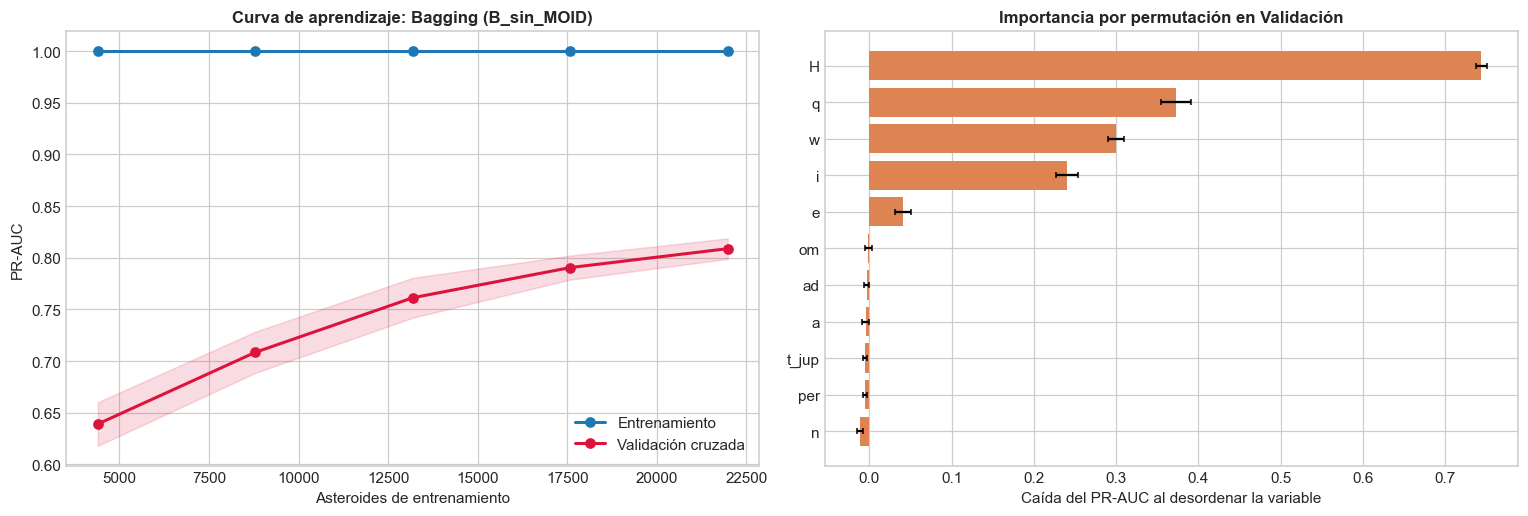

,Filas de entrenamiento,PR-AUC Train,PR-AUC CV,Desv. CV
0,4395,1.0,0.6390,0.0211
1,8790,1.0,0.7084,0.0199
2,13186,1.0,0.7612,0.0193
3,17581,1.0,0.7904,0.0116
4,21977,1.0,0.8087,0.0099


,Caída de PR-AUC,Desv.
H,0.7439,0.0065
q,0.3732,0.0181
w,0.3000,0.0094
i,0.2403,0.0132
e,0.0408,0.0098
om,-0.0010,0.0037
ad,-0.0030,0.0031
a,-0.0044,0.0046
t_jup,-0.0053,0.0027
per,-0.0055,0.0020


In [9]:
# 5.2 Sobreajuste: brecha Train - CV, curva de aprendizaje e importancia por permutación (modelo del escenario B)
brecha = df_bench[df_bench['Modelo'] != 'Baseline (Mayoritaria)'].assign(brecha=lambda d: d['train_pr_auc'] - d['pr_auc'])
BRECHA_TRAIN_CV = brecha.pivot(index='Modelo', columns='Escenario', values='brecha')[list(ESCENARIOS)]
print('Diferencia de PR-AUC entre entrenamiento y validación cruzada (Train - CV):')
display(BRECHA_TRAIN_CV.sort_values(ESCENARIO_FOCO).round(4))

r_b = resultados[ESCENARIO_FOCO]
tam_lc, pr_tr_lc, pr_cv_lc = learning_curve(
    clone(MODELOS[r_b['modelo_nombre']]), train[cols_b], y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), scoring='average_precision',
    train_sizes=np.linspace(0.2, 1.0, 5), shuffle=True, random_state=SEED, n_jobs=-1)
CURVA_APRENDIZAJE = pd.DataFrame({'Filas de entrenamiento': tam_lc, 'PR-AUC Train': pr_tr_lc.mean(1),
                                  'PR-AUC CV': pr_cv_lc.mean(1), 'Desv. CV': pr_cv_lc.std(1)})

perm = permutation_importance(r_b['modelo'], val[cols_b], y_val, scoring='average_precision', n_repeats=10,
                              random_state=SEED, n_jobs=-1)
IMPORTANCIA_PERM = pd.DataFrame({'Caída de PR-AUC': perm.importances_mean, 'Desv.': perm.importances_std},
                                index=cols_b).sort_values('Caída de PR-AUC', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(tam_lc, pr_tr_lc.mean(1), marker='o', lw=2, label='Entrenamiento')
axes[0].plot(tam_lc, pr_cv_lc.mean(1), marker='o', lw=2, color='crimson', label='Validación cruzada')
axes[0].fill_between(tam_lc, pr_cv_lc.mean(1) - pr_cv_lc.std(1), pr_cv_lc.mean(1) + pr_cv_lc.std(1), color='crimson', alpha=0.15)
axes[0].set_title(f"Curva de aprendizaje: {r_b['modelo_nombre']} ({ESCENARIO_FOCO})")
axes[0].set_xlabel('Asteroides de entrenamiento'); axes[0].set_ylabel('PR-AUC'); axes[0].legend(loc='lower right')
top = IMPORTANCIA_PERM[::-1]
axes[1].barh(top.index, top['Caída de PR-AUC'], xerr=top['Desv.'], color='#DD8452', capsize=2)
axes[1].set_title('Importancia por permutación en Validación')
axes[1].set_xlabel('Caída del PR-AUC al desordenar la variable')
plt.tight_layout()
plt.show()
display(CURVA_APRENDIZAJE.round(4))
display(IMPORTANCIA_PERM.round(4))

<a id="j5-3"></a>
### 5.3 Evaluación en Test

Con todo decidido, evaluamos una sola vez en los asteroides descubiertos de 2024 en adelante: métricas con el umbral F2 escogido en Validación y con el umbral de 0.5, cuántos peligrosos se detectan con cada uno y la tasa de alertas. Validación tiene asteroides del mismo periodo que Train y Test tiene asteroides posteriores: comparar los dos muestra cuánto cambia el desempeño cuando la población cambia con el tiempo.

,Modelo,Umbral F2,Val PR-AUC,Test PR-AUC,Val Recall,Test Recall,Val Precision,Test Precision,Val F2,Test F2,Test PHA detectados,Test falsas alarmas,Test Recall (umbral 0.5),CV PR-AUC (media ± std),Test PHA detectados (umbral 0.5),Tasa de alertas Val,Tasa de alertas Test
Escenario,,,,,,,,,,,,,,,,,
A_completo,Random Forest,0.165,0.9984,0.9976,0.9959,1.0000,0.9699,0.9023,0.9906,0.9788,120 de 120,13,0.9917,0.9961 ± 0.0022,119 de 120,0.0727,0.0161
B_sin_MOID,Bagging,0.220,0.8650,0.7843,0.9671,0.9917,0.5942,0.4146,0.8592,0.7757,119 de 120,168,0.2833,0.8091 ± 0.0125,34 de 120,0.1152,0.0348
C_sin_definicion,Gradient Boosting,0.088,0.2241,0.0983,0.7325,0.8167,0.1668,0.0410,0.4365,0.1706,98 de 120,2295,0.0000,0.1984 ± 0.0084,0 de 120,0.3107,0.2903


Umbral F2 vs 0.5 en Test (120 peligrosos de 8,242 asteroides):


Valor  Recall  Precision      F2  \
Escenario        Umbral                                              
A_completo       F2 (Validación)  0.165  1.0000     0.9023  0.9788   
                 0.5              0.500  0.9917     0.9597  0.9851   
B_sin_MOID       F2 (Validación)  0.220  0.9917     0.4146  0.7757   
                 0.5              0.500  0.2833     0.8947  0.3282   
C_sin_definicion F2 (Validación)  0.088  0.8167     0.0410  0.1706   
                 0.5              0.500  0.0000     0.0000  0.0000   

                                  Peligrosos sin detectar  Falsas alarmas  \
Escenario        Umbral                                                     
A_completo       F2 (Validación)                        0              13   
                 0.5                                    1               5   
B_sin_MOID       F2 (Validación)                        1             168   
                 0.5                                   86               4   
C_sin_definicion F2 (Validación)                       22            2295   
                 0.5                                  120               3   

                                  Tasa de alertas  
Escenario        Umbral                            
A_completo       F2 (Validación)           0.0161  
                 0.5                       0.0150  
B_sin_MOID       F2 (Validación)           0.0348  
                 0.5                       0.0046  
C_sin_definicion F2 (Validación)           0.2903  
                 0.5                       0.0004

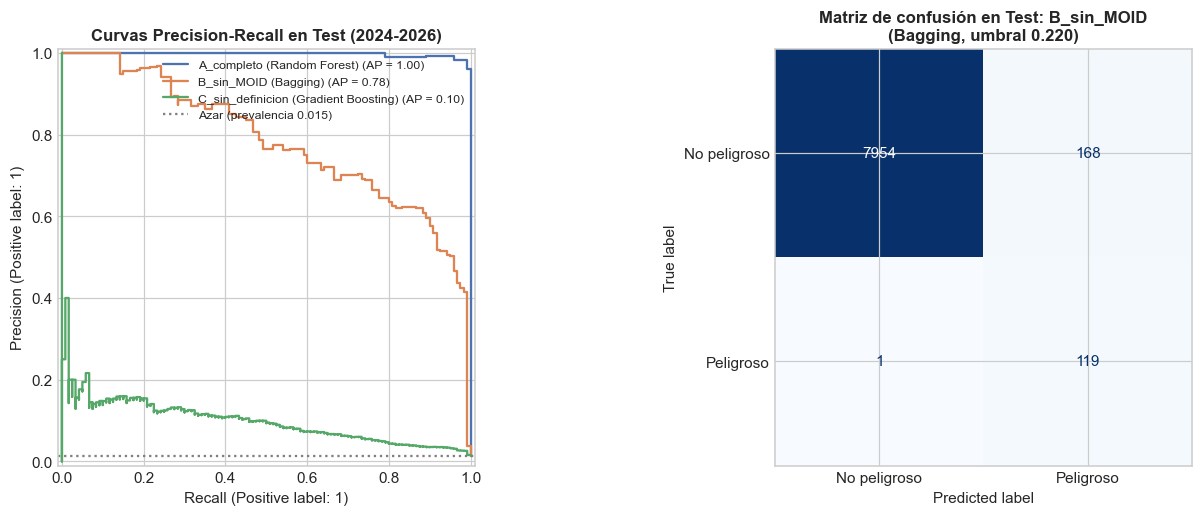

In [10]:
# 5.3 Evaluación en Test (una sola vez, con modelo y umbral ya fijos)
for esc, r in resultados.items():
    cols = columnas_escenario(esc)
    r['probs_test'] = r['modelo'].predict_proba(test[cols])[:, 1]
    r['test'] = metricas_binarias(y_test, r['probs_test'], r['umbral'])
    r['test_umbral_05'] = metricas_binarias(y_test, r['probs_test'], 0.5)
    r['tasa_alertas'] = {'validacion': r['val']['tasa_alertas'], 'test': r['test']['tasa_alertas']}

tabla_eval = pd.DataFrame([{
    'Escenario': esc, 'Modelo': r['modelo_nombre'], 'Umbral F2': round(r['umbral'], 3),
    'Val PR-AUC': r['val']['pr_auc'], 'Test PR-AUC': r['test']['pr_auc'],
    'Val Recall': r['val']['recall'], 'Test Recall': r['test']['recall'],
    'Val Precision': r['val']['precision'], 'Test Precision': r['test']['precision'],
    'Val F2': r['val']['f2'], 'Test F2': r['test']['f2'],
    'Test PHA detectados': f"{r['test']['positivos'] - r['test']['falsos_negativos']} de {r['test']['positivos']}",
    'Test falsas alarmas': r['test']['falsos_positivos'],
    'Test Recall (umbral 0.5)': r['test_umbral_05']['recall'],
    'CV PR-AUC (media ± std)': f"{r['cv_pr_auc']:.4f} ± {r['cv_pr_auc_std']:.4f}",
    'Test PHA detectados (umbral 0.5)': f"{r['test_umbral_05']['positivos'] - r['test_umbral_05']['falsos_negativos']} de {r['test']['positivos']}",
    'Tasa de alertas Val': r['tasa_alertas']['validacion'], 'Tasa de alertas Test': r['tasa_alertas']['test']
} for esc, r in resultados.items()]).set_index('Escenario')
display(tabla_eval.round(4))

COMPARACION_UMBRAL = pd.DataFrame([{
    'Escenario': esc, 'Umbral': nombre_u, 'Valor': round(u, 3), 'Recall': m['recall'], 'Precision': m['precision'], 'F2': m['f2'],
    'Peligrosos sin detectar': m['falsos_negativos'], 'Falsas alarmas': m['falsos_positivos'], 'Tasa de alertas': m['tasa_alertas']}
    for esc, r in resultados.items()
    for nombre_u, u, m in [('F2 (Validación)', r['umbral'], r['test']), ('0.5', 0.5, r['test_umbral_05'])]
]).set_index(['Escenario', 'Umbral'])
print(f'Umbral F2 vs 0.5 en Test ({int(y_test.sum())} peligrosos de {len(y_test):,} asteroides):')
display(COMPARACION_UMBRAL.round(4))

# Curvas Precision-Recall en Test y matriz de confusión del escenario de interés
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colores = {'A_completo': '#4C72B0', 'B_sin_MOID': '#DD8452', 'C_sin_definicion': '#55A868'}
for esc, r in resultados.items():
    PrecisionRecallDisplay.from_predictions(y_test, r['probs_test'], name=f"{esc} ({r['modelo_nombre']})",
                                            ax=axes[0], color=colores[esc])
axes[0].axhline(y_test.mean(), color='gray', ls=':', label=f'Azar (prevalencia {y_test.mean():.3f})')
axes[0].set_title(f'Curvas Precision-Recall en Test ({ANIO_CORTE}-{ANIO_ACTUAL})')
axes[0].legend(fontsize=8, loc='upper right')
r_foco = resultados[ESCENARIO_FOCO]
ConfusionMatrixDisplay.from_predictions(y_test, (r_foco['probs_test'] >= r_foco['umbral']).astype(int),
                                        display_labels=['No peligroso', 'Peligroso'], cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title(f"Matriz de confusión en Test: {ESCENARIO_FOCO}\n({r_foco['modelo_nombre']}, umbral {r_foco['umbral']:.3f})")
plt.tight_layout()
plt.show()

<a id="j5-4"></a>
### 5.4 Intervalos de confianza en Test

Test tiene unos 120 peligrosos, así que una o dos detecciones mueven el recall casi un punto. Repetimos 1,000 veces la evaluación sobre muestras de Test con reemplazo (*bootstrap*; aquí cada fila es un asteroide distinto). El modelo y el umbral no cambian.

In [11]:
# 5.4 Bootstrap sobre Test (modelo y umbral fijos)
rng = np.random.default_rng(SEED)
filas_ic = []
for esc, r in resultados.items():
    muestras = []
    for _ in range(1000):
        s = rng.integers(0, len(y_test), len(y_test))
        m = metricas_binarias(y_test[s], r['probs_test'][s], r['umbral'])
        muestras.append({k: m[k] for k in ['pr_auc', 'roc_auc', 'recall', 'precision', 'f2']})
    bs = pd.DataFrame(muestras)
    for k in bs.columns:
        filas_ic.append({'Escenario': esc, 'Métrica': k, 'Test': r['test'][k],
                         'IC 95% inferior': bs[k].quantile(0.025), 'IC 95% superior': bs[k].quantile(0.975)})
df_ic = pd.DataFrame(filas_ic)
display(df_ic.set_index(['Escenario', 'Métrica']).round(3))

Test  IC 95% inferior  IC 95% superior
Escenario        Métrica                                           
A_completo       pr_auc     0.998            0.993            1.000
                 roc_auc    1.000            1.000            1.000
                 recall     1.000            1.000            1.000
                 precision  0.902            0.856            0.953
                 f2         0.979            0.967            0.990
B_sin_MOID       pr_auc     0.784            0.715            0.849
                 roc_auc    0.994            0.987            0.997
                 recall     0.992            0.972            1.000
                 precision  0.415            0.358            0.472
                 f2         0.776            0.733            0.814
C_sin_definicion pr_auc     0.098            0.072            0.144
                 roc_auc    0.867            0.836            0.891
                 recall     0.817            0.745            0.878
                 precision  0.041            0.033            0.050
                 f2         0.171            0.141            0.201

<a id="j6"></a>
## 6. Desempeño según la calidad de la órbita y en los asteroides grandes

Dentro de Test separamos los asteroides según qué tan bien se conoce su órbita (`condition_code`) y cuántos días se han observado (`data_arc`). Un asteroide recién descubierto suele tener pocos días de observación y una órbita incierta (U 7–9).

Miramos el modelo del escenario B en dos grupos:

1. Todos los asteroides de Test.
2. Solo los grandes ($H \le 22$), que son los únicos que pueden ser peligrosos según la definición. Con los pequeños el modelo acierta fácil porque le basta mirar H; con los grandes está la parte difícil.

**Por qué baja la precisión en Test.** La precisión depende de dos cosas: cuántos peligrosos hay en el conjunto (si hay menos, una parte mayor de las alertas son falsas alarmas) y cuántas falsas alarmas marca el modelo por cada asteroide no peligroso. Entre los descubiertos hasta 2023 el 7.1% es peligroso y entre los de 2024 en adelante solo el 1.5%. Al final de esta sección comparamos la proporción de peligrosos, la precisión y el recall en Train, Validación, Test y en los asteroides grandes de Test.


Por calidad de órbita: Todos los asteroides de Test


,Asteroides,PHA reales,% PHA,PHA detectados,Recall,Precision,F2,PR-AUC,Falsas alarmas
Grupo,,,,,,,,,
Todos,8242,120,0.015,119,0.992,0.415,0.776,0.784,168
Buena (U 0-3),156,17,0.109,17,1.000,0.607,0.885,0.792,11
Media (U 4-6),2432,63,0.026,62,0.984,0.437,0.787,0.792,80
Incierta (U 7-9),5653,40,0.007,40,1.000,0.342,0.722,0.801,77



Por calidad de órbita: Solo grandes (H <= 22)


,Asteroides,PHA reales,% PHA,PHA detectados,Recall,Precision,F2,PR-AUC,Falsas alarmas
Grupo,,,,,,,,,
Todos,792,120,0.152,119,0.992,0.431,0.787,0.789,157
Buena (U 0-3),54,17,0.315,17,1.000,0.607,0.885,0.792,11
Media (U 4-6),463,63,0.136,62,0.984,0.449,0.795,0.796,76
Incierta (U 7-9),274,40,0.146,40,1.000,0.364,0.741,0.804,70



Por días de observación: solo grandes (H <= 22)


,Asteroides,PHA reales,% PHA,PHA detectados,Recall,Precision,F2,PR-AUC,Falsas alarmas
Grupo,,,,,,,,,
Todos,792,120,0.152,119,0.992,0.431,0.787,0.789,157
< 30 días,260,37,0.142,37,1.000,0.370,0.746,0.781,63
30 días - 1 año,516,73,0.141,72,0.986,0.442,0.791,0.811,91
> 1 año,16,10,0.625,10,1.000,0.769,0.943,0.892,3


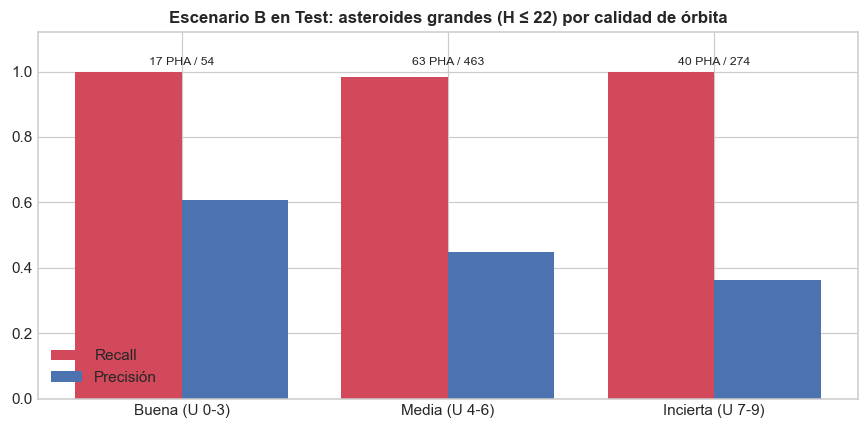

,% PHA,Precision,Recall
Conjunto,,,
Train (hasta 2023),0.071,NaN,NaN
Validación (hasta 2023),0.071,0.594,0.967
"Test, todos",0.015,0.415,0.992
"Test, solo grandes (H <= 22)",0.152,0.431,0.992


In [12]:
# 6. Desempeño del escenario B por calidad de órbita y por días de observación
test['prob_B'] = r_foco['probs_test']
test['arco'] = pd.cut(test['data_arc'], [-np.inf, 30, 365, np.inf],
                      labels=['< 30 días', '30 días - 1 año', '> 1 año'])


def tabla_por_grupo(datos: pd.DataFrame, columna: str, umbral: float) -> pd.DataFrame:
    """Métricas del modelo para todo el conjunto y para cada categoría de `columna`."""
    grupos = [('Todos', datos)] + [(str(k), g) for k, g in datos.groupby(columna, observed=True)]
    filas = []
    for nombre, g in grupos:
        m = metricas_binarias(g[TARGET].to_numpy(), g['prob_B'].to_numpy(), umbral)
        filas.append({'Grupo': nombre, 'Asteroides': len(g), 'PHA reales': m['positivos'],
                      '% PHA': g[TARGET].mean(), 'PHA detectados': m['positivos'] - m['falsos_negativos'],
                      'Recall': m['recall'], 'Precision': m['precision'], 'F2': m['f2'],
                      'PR-AUC': m['pr_auc'], 'Falsas alarmas': m['falsos_positivos']})
    return pd.DataFrame(filas).set_index('Grupo')


umbral_B = r_foco['umbral']
grandes = test[test['H'] <= 22]
tablas_calidad = {
    'Todos los asteroides de Test': tabla_por_grupo(test, 'calidad_orbita', umbral_B),
    'Solo grandes (H <= 22)': tabla_por_grupo(grandes, 'calidad_orbita', umbral_B)
}
for titulo, t in tablas_calidad.items():
    print(f'\nPor calidad de órbita: {titulo}')
    display(t.round(3))
tabla_arco = tabla_por_grupo(grandes, 'arco', umbral_B)
print('\nPor días de observación: solo grandes (H <= 22)')
display(tabla_arco.round(3))

# Recall y precisión por calidad de órbita (solo grandes)
t_plot = tablas_calidad['Solo grandes (H <= 22)'].drop(index='Todos')
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(t_plot))
ax.bar(x - 0.2, t_plot['Recall'], width=0.4, label='Recall', color='#D1495B')
ax.bar(x + 0.2, t_plot['Precision'], width=0.4, label='Precisión', color='#4C72B0')
for xi, (n_pha, n_tot) in enumerate(zip(t_plot['PHA reales'], t_plot['Asteroides'])):
    ax.text(xi, 1.02, f'{n_pha} PHA / {n_tot}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(t_plot.index)
ax.set_ylim(0, 1.12)
ax.set_title(f'Escenario B en Test: asteroides grandes (H ≤ 22) por calidad de órbita')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

# Proporción de peligrosos, precisión y recall del modelo B: la precisión sigue a la proporción de peligrosos
t_todos = tablas_calidad['Todos los asteroides de Test'].loc['Todos']
t_grandes = tablas_calidad['Solo grandes (H <= 22)'].loc['Todos']
PREVALENCIA_Y_PRECISION = pd.DataFrame([
    {'Conjunto': f'Train (hasta {ANIO_CORTE - 1})', '% PHA': y_train.mean()},
    {'Conjunto': f'Validación (hasta {ANIO_CORTE - 1})', '% PHA': y_val.mean(),
     'Precision': r_foco['val']['precision'], 'Recall': r_foco['val']['recall']},
    {'Conjunto': 'Test, todos', '% PHA': y_test.mean(), 'Precision': t_todos['Precision'], 'Recall': t_todos['Recall']},
    {'Conjunto': 'Test, solo grandes (H <= 22)', '% PHA': t_grandes['% PHA'], 'Precision': t_grandes['Precision'],
     'Recall': t_grandes['Recall']},
]).set_index('Conjunto')
display(PREVALENCIA_Y_PRECISION.round(3))

<a id="j7"></a>
## 7. Cambio entre el entrenamiento y los recién descubiertos (Operate & Optimize)

Comparamos cómo se reparten el tamaño (`H`) y la distancia del perihelio (`q`) en Train y en Test, que aquí es un lote real de asteroides descubiertos después del corte. Si los recién descubiertos son distintos, el modelo tiene que aguantar ese cambio. La tasa de alertas dice si el modelo marca una proporción parecida de asteroides en Validación y en Test.

,Train (< 2024),Test (2024-2026)
H mediana,23.720,25.130
% grandes (H <= 22),0.321,0.096
q mediana (UA),0.962,0.956
% PHA,0.071,0.015


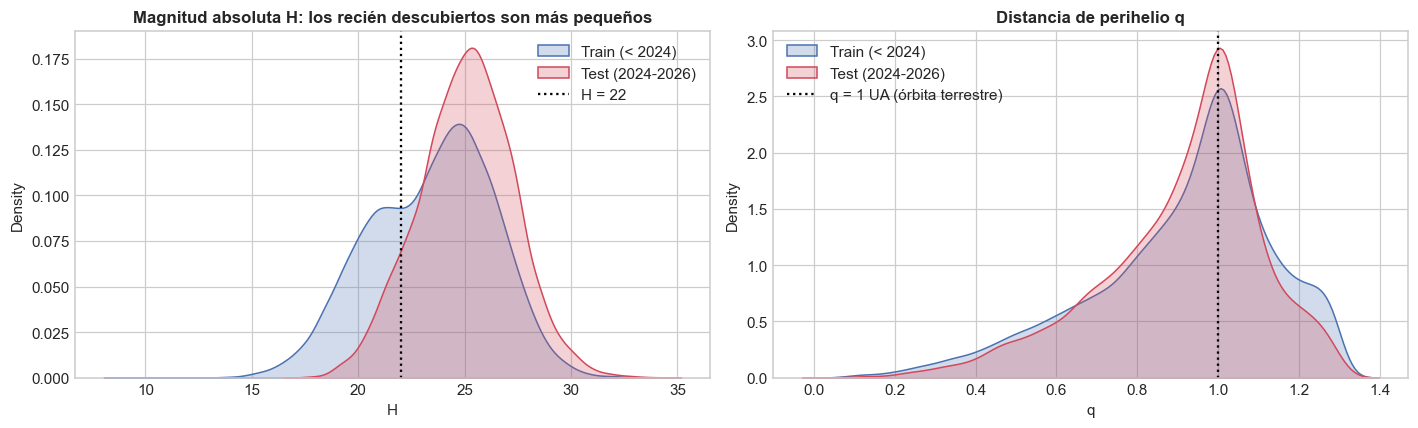

Tasa de alertas del modelo B: Validación 11.5% -> Test 3.5% (-8.0 pp). Prevalencia real: 7.1% -> 1.5%.


In [13]:
# 7. Tamaño y perihelio: Train frente a los recién descubiertos (Test)
CAMBIO_POBLACION = pd.DataFrame({
    nombre: {'H mediana': d['H'].median(), '% grandes (H <= 22)': (d['H'] <= 22).mean(), 'q mediana (UA)': d['q'].median(),
             '% PHA': d[TARGET].mean()}
    for nombre, d in [(f'Train (< {ANIO_CORTE})', train), (f'Test ({ANIO_CORTE}-{ANIO_ACTUAL})', test)]
})
display(CAMBIO_POBLACION.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for d, etiqueta, color in [(train, f'Train (< {ANIO_CORTE})', '#4C72B0'), (test, f'Test ({ANIO_CORTE}-{ANIO_ACTUAL})', '#D1495B')]:
    sns.kdeplot(d['H'], ax=axes[0], label=etiqueta, color=color, fill=True, alpha=0.25)
    sns.kdeplot(d['q'], ax=axes[1], label=etiqueta, color=color, fill=True, alpha=0.25)
axes[0].axvline(22, color='black', ls=':', label='H = 22')
axes[0].set_title('Magnitud absoluta H: los recién descubiertos son más pequeños')
axes[1].axvline(1.0, color='black', ls=':', label='q = 1 UA (órbita terrestre)')
axes[1].set_title('Distancia de perihelio q')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

tasa_ref = float((r_foco['probs_val'] >= umbral_B).mean())
tasa_test = float((r_foco['probs_test'] >= umbral_B).mean())
print(f'Tasa de alertas del modelo B: Validación {tasa_ref:.1%} -> Test {tasa_test:.1%} '
      f'({100 * (tasa_test - tasa_ref):+.1f} pp). Prevalencia real: {y_val.mean():.1%} -> {y_test.mean():.1%}.')

<a id="j8"></a>
## 8. Resultados y conclusiones

<a id="j8-1"></a>
### 8.1 Cifras clave

Las cifras de las conclusiones salen de esta tabla. También se guardan en `resultados/jpl_*`.

In [14]:
# 8.1 Cifras clave y exportación (resultados/jpl_*)
t_grandes_cal = tablas_calidad['Solo grandes (H <= 22)']


def ic(esc: str, metrica: str) -> str:
    fila = df_ic[(df_ic['Escenario'] == esc) & (df_ic['Métrica'] == metrica)].iloc[0]
    return f"{fila['IC 95% inferior']:.3f} a {fila['IC 95% superior']:.3f}"


segundo_b = rankings[ESCENARIO_FOCO].iloc[1]
resumen = {
    'Catálogo (fecha de descarga)': f'{len(cat):,} NEOs válidos ({FECHA_CATALOGO})',
    'Acuerdo regla CNEOS vs etiqueta': f'{ACUERDO_REGLA:.2%}',
    '% PHA: Train vs Validación vs Test': f'{y_train.mean():.2%} vs {y_val.mean():.2%} vs {y_test.mean():.2%}',
    'H mediana: Train vs Test': f"{train['H'].median():.1f} vs {test['H'].median():.1f}",
    'Ganador A / B / C': ' / '.join(resultados[e]['modelo_nombre'] for e in ESCENARIOS),
    'CV PR-AUC ganador A / B / C (media ± std)': ' / '.join(
        f"{resultados[e]['cv_pr_auc']:.4f} ± {resultados[e]['cv_pr_auc_std']:.4f}" for e in ESCENARIOS),
    'Segundo en B y diferencia de PR-AUC': f"{segundo_b['Modelo']} ({r_foco['cv_pr_auc'] - segundo_b['pr_auc']:.4f}, "
                                           f"desviación {r_foco['cv_pr_auc_std']:.4f})",
    'Ventanas de años: PR-AUC en 2021-2023': ' / '.join(f'{k}: {v:.3f}' for k, v in df_ventanas['PR-AUC (2021-2023)'].items()),
    'MOID calculado vs MOID del JPL': f'correlación {CORR_MOID:.4f}, mismo lado de 0.05 UA en el {ACUERDO_MOID:.1%}',
    'CV PR-AUC B / B + geometría / A': ' / '.join(f'{v:.4f}' for v in df_geo['pr_auc']),
    'Brecha Train - CV del ganador B': f"{BRECHA_TRAIN_CV.loc[r_foco['modelo_nombre'], ESCENARIO_FOCO]:.4f}",
    'PR-AUC Val -> Test (B)': f"{r_foco['val']['pr_auc']:.4f} -> {r_foco['test']['pr_auc']:.4f}",
    'IC 95% PR-AUC Test (B)': ic(ESCENARIO_FOCO, 'pr_auc'),
    'Recall Val -> Test (B)': f"{r_foco['val']['recall']:.4f} -> {r_foco['test']['recall']:.4f}",
    'Precisión Val -> Test (B)': f"{r_foco['val']['precision']:.4f} -> {r_foco['test']['precision']:.4f}",
    'PHA detectados en Test (B), umbral F2 vs 0.5': f"{r_foco['test']['positivos'] - r_foco['test']['falsos_negativos']} vs "
                                                    f"{r_foco['test_umbral_05']['positivos'] - r_foco['test_umbral_05']['falsos_negativos']} "
                                                    f"de {r_foco['test']['positivos']}",
    'Falsas alarmas en Test (B)': f"{r_foco['test']['falsos_positivos']:,} de {int((y_test == 0).sum()):,} no peligrosos",
    'Tasa de alertas (B): Validación / Test': f"{r_foco['tasa_alertas']['validacion']:.1%} / {r_foco['tasa_alertas']['test']:.1%}",
    'Precisión en Test: todos / solo grandes (H <= 22)': f"{PREVALENCIA_Y_PRECISION.loc['Test, todos', 'Precision']:.3f} / "
                                                         f"{PREVALENCIA_Y_PRECISION.loc['Test, solo grandes (H <= 22)', 'Precision']:.3f}",
    'Recall grandes por calidad (Buena / Media / Incierta)': ' / '.join(
        f"{t_grandes_cal.loc[g, 'Recall']:.3f}" if g in t_grandes_cal.index else 'n/a'
        for g in ['Buena (U 0-3)', 'Media (U 4-6)', 'Incierta (U 7-9)'])
}
display(pd.Series(resumen, name='Valor').to_frame())

df_bench.to_csv(RESULTADOS / 'jpl_benchmark_cv.csv', index=False)
tabla_eval.to_csv(RESULTADOS / 'jpl_evaluacion_test.csv')
pd.concat(tablas_calidad, names=['Poblacion']).to_csv(RESULTADOS / 'jpl_test_por_calidad_orbita.csv')
df_ic.to_csv(RESULTADOS / 'jpl_intervalos_confianza_test.csv', index=False)
(RESULTADOS / 'jpl_metrics_summary.json').write_text(json.dumps({
    'fecha_catalogo': FECHA_CATALOGO, 'anio_corte': ANIO_CORTE, 'resumen': resumen,
    'evaluacion': {esc: {k: r[k] for k in ['modelo_nombre', 'umbral', 'val', 'test', 'test_umbral_05',
                                           'cv_pr_auc', 'cv_pr_auc_std', 'f2_val', 'tasa_alertas']}
                   for esc, r in resultados.items()},
    'ventanas_anios': {'evaluadas_con': f'{ANIO_RECIENTES}-{ANIO_CORTE - 1}', 'mejor': MEJOR_VENTANA,
                       'comparacion': json.loads(df_ventanas.reset_index().to_json(orient='records'))},
    'cambio_poblacion': json.loads(CAMBIO_POBLACION.to_json()),
    'moid_desde_orbita': {'correlacion': CORR_MOID, 'acuerdo_umbral_005': ACUERDO_MOID, 'cv': df_geo.reset_index().to_dict(orient='records')},
    'sobreajuste': {'brecha_train_cv': BRECHA_TRAIN_CV.to_dict(), 'curva_aprendizaje': CURVA_APRENDIZAJE.to_dict(orient='list'),
                    'importancia_permutacion': IMPORTANCIA_PERM['Caída de PR-AUC'].to_dict()},
    'umbral_f2_vs_05': COMPARACION_UMBRAL.reset_index().to_dict(orient='records'),
    'prevalencia_y_precision': json.loads(PREVALENCIA_Y_PRECISION.reset_index().to_json(orient='records')),
    'intervalos_test': df_ic.to_dict(orient='records')
}, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, 'item') else str(o)), encoding='utf-8')
print('Exportado:', sorted(p.name for p in RESULTADOS.glob('jpl_*')))

,Valor
Catálogo (fecha de descarga),"42,582 NEOs válidos (2026-10-11)"
Acuerdo regla CNEOS vs etiqueta,99.88%
% PHA: Train vs Validación vs Test,7.08% vs 7.08% vs 1.46%
H mediana: Train vs Test,23.7 vs 25.1
Ganador A / B / C,Random Forest / Bagging / Gradient Boosting
CV PR-AUC ganador A / B / C (media ± std),0.9961 ± 0.0022 / 0.8091 ± 0.0125 / 0.1984 ± 0.0084
Segundo en B y diferencia de PR-AUC,"Gradient Boosting (0.0529, desviación 0.0125)"
Ventanas de años: PR-AUC en 2021-2023,Todos (hasta 2020): 0.859 / Desde 2000: 0.841 / Desde 2010: 0.832 / Desde 2015: 0.798
MOID calculado vs MOID del JPL,"correlación 0.9967, mismo lado de 0.05 UA en el 96.9%"
CV PR-AUC B / B + geometría / A,0.8091 / 0.9602 / 0.9944


Exportado: ['jpl_benchmark_cv.csv', 'jpl_evaluacion_test.csv', 'jpl_intervalos_confianza_test.csv', 'jpl_metrics_summary.json', 'jpl_test_por_calidad_orbita.csv']


<a id="j8-2"></a>
### 8.2 Datos para la presentación

Exportamos a `resultados/presentacion_jpl.json` los datos de las gráficas de la presentación web, sin recalcular nada.

In [15]:
# 8.2 Datos de las gráficas para la presentación web (carpeta presentacion/)
# Solo se exportan números ya calculados arriba: la presentación los dibuja, nunca los recalcula.
calidad_periodo = (pd.crosstab(cat['periodo'], cat['calidad_orbita'], normalize='index') * 100).round(1)
presentacion_jpl = {
    'catalogo': {'validos': int(len(cat)), 'pha': int(cat[TARGET].sum()), 'acuerdo_regla': ACUERDO_REGLA,
                 'fecha': FECHA_CATALOGO},
    'anio_corte': ANIO_CORTE, 'anio_actual': ANIO_ACTUAL,
    'por_anio': por_anio.loc[2000:].reset_index().round(4).to_dict(orient='records'),
    'periodos': resumen_periodo.reset_index().round(4).to_dict(orient='records'),
    'calidad_por_periodo': {str(p): {str(k): float(v) for k, v in fila.items()} for p, fila in calidad_periodo.iterrows()},
    'particion': {'train': int(len(train)), 'validacion': int(len(val)), 'test': int(len(test)),
                  'pha_train': int(y_train.sum()), 'pha_validacion': int(y_val.sum()), 'pha_test': int(y_test.sum())},
    'por_arco_grandes': tabla_arco.reset_index().round(4).to_dict(orient='records'),
    'alertas_b': {'tasa_validacion': tasa_ref, 'tasa_test': tasa_test},
}
(RESULTADOS / 'presentacion_jpl.json').write_text(
    json.dumps(presentacion_jpl, indent=1, ensure_ascii=False, default=float), encoding='utf-8')
print('Guardado resultados/presentacion_jpl.json:', ', '.join(presentacion_jpl))

Guardado resultados/presentacion_jpl.json:

 catalogo, anio_corte, anio_actual, por_anio, periodos, calidad_por_periodo, particion, por_arco_grandes, alertas_b


<a id="j8-3"></a>
### 8.3 Conclusiones

Cifras de la tabla de [8.1](#j8-1) y de las tablas anteriores (catálogo descargado el 2026-10-11, `SEED = 42`).

**1. La etiqueta es una regla física, y el modelo la puede rearmar.** La etiqueta oficial coincide con la regla (MOID ≤ 0.05 y H ≤ 22) en el 99.88% de los 42,582 asteroides. Además, el MOID se puede calcular desde la órbita: nuestro cálculo tiene correlación 0.997 con el del JPL y cae del mismo lado de 0.05 UA en el 96.9% de los casos. Si al Bagging del escenario B le damos seis variables de geometría orbital, su PR-AUC en validación cruzada pasa de 0.809 a 0.960, cerca del 0.994 del escenario A: con la órbita bien descrita, el modelo vuelve a construir la regla. Esas variables quedaron solo como análisis; el modelo evaluado usa las variables originales.

**2. Los asteroides que se descubren hoy son distintos.** El 7.1% de los descubiertos hasta 2023 es peligroso y solo el 1.5% de los de 2024 en adelante. La H mediana pasa de 23.7 en Train a 25.1 en Test (objetos más pequeños) y los grandes ($H \le 22$) bajan del 32.1% al 9.6%. La órbita, en cambio, casi no cambia: el perihelio mediano es 0.96 UA en los dos conjuntos.

**3. Bagging es el mejor modelo sin MOID.** En el escenario B logra PR-AUC 0.809 ± 0.013 en validación cruzada, frente a 0.756 ± 0.019 de Gradient Boosting: una diferencia clara, mayor que la desviación. En A, Random Forest y Gradient Boosting empatan (≈ 0.996) y en C, Gradient Boosting y Bagging (≈ 0.198): esas diferencias no son concluyentes.

**4. Entrenar solo con años recientes no ayuda.** Entrenando con lo descubierto hasta 2020 y evaluando con lo descubierto entre 2021 y 2023, usar todos los años da el mayor PR-AUC (0.859). Las ventanas desde 2000 (0.841), desde 2010 (0.832) y desde 2015 (0.798) tienen asteroides más parecidos a los recientes (H mediana de 23.3 a 24.3), pero pierden datos y peligrosos para aprender. Por eso el modelo se entrena con todos los años.

**5. El modelo no memoriza y no mira solo el tamaño.** La diferencia entre el PR-AUC de entrenamiento y el de validación cruzada es 0.191 para Bagging, menor que Random Forest (0.256) y mayor que Gradient Boosting (0.059). La curva de aprendizaje sigue subiendo (de 0.639 con el 20% de Train a 0.809 con todo), así que más datos ayudarían. En la importancia por permutación, H es la variable que más pesa (0.74), pero le siguen el perihelio `q` (0.37), el argumento del perihelio `w` (0.30) y la inclinación `i` (0.24): justo los elementos con los que se calcula el MOID.

**6. Resultado con los asteroides de 2024 en adelante (escenario B).** Con el umbral escogido en Validación (0.22), el modelo detecta **119 de los 120** peligrosos (recall 0.992, IC 95%: 0.972 a 1.000) con 168 falsas alarmas entre 8,122 no peligrosos. PR-AUC = 0.784 (IC 95%: 0.715 a 0.849), precisión = 0.415 y F2 = 0.776. En la práctica, de 8,242 asteroides marca 287 (3.5%) para revisar, y en esa lista están casi todos los peligrosos.

**7. Mover el umbral es lo que hace útil al modelo.** Con el umbral de 0.5 el modelo detectaría solo 34 de 120 peligrosos; con el umbral F2 detecta 119, a cambio de 168 falsas alarmas en vez de 4. La tasa de alertas pasa de 11.5% en Validación a 3.5% en Test porque entre los recién descubiertos hay muchos menos peligrosos.

**8. Por qué baja la precisión.** De Validación a Test la precisión baja de 0.594 a 0.415 mientras el recall sube de 0.967 a 0.992: no se escapan más peligrosos. La baja viene de que hay menos peligrosos (7.1% → 1.5%), no de que el modelo se equivoque más: marca como peligroso al 5.0% de los no peligrosos en Validación (321 de 6,382) y solo al 2.1% en Test (168 de 8,122). Entre los asteroides grandes de Test (H ≤ 22) la precisión es 0.431, porque 157 de las 168 falsas alarmas son grandes: el modelo ya descarta los pequeños por H, y lo difícil es la frontera de 0.05 UA del MOID.

**9. Que la órbita sea incierta casi no le afecta.** Entre los grandes, el modelo detectó el 100%, el 98.4% y el 100% de los peligrosos con órbita buena, media e incierta, y 37 de 37 de los observados menos de 30 días. Ojo: la etiqueta de un asteroide con órbita incierta se calcula con esa misma órbita provisional, así que algunos podrían cambiar de clase cuando su órbita se conozca mejor.

**10. El tamaño es indispensable.** Sin H (escenario C) el modelo no puede: PR-AUC de 0.098 en Test y 2,295 falsas alarmas para encontrar 98 de 120 peligrosos. Sin tamaño no hay forma de separar un asteroide de 140 m de uno de 20 m con la misma órbita, y los recién descubiertos son casi todos pequeños.

**¿Para qué sirve en la práctica?** La NASA calcula el MOID en cuanto un asteroide tiene órbita, así que este modelo no reemplaza ese cálculo. Lo que muestra es que, sin MOID y con datos de años anteriores, un modelo encuentra a 119 de 120 peligrosos entre los recién descubiertos revisando solo el 3.5% de ellos, aunque la población cambie y las órbitas sean inciertas.

**Limitaciones**

1. Test tiene 120 peligrosos; por eso reportamos intervalos de confianza ([5.4](#j5-4)): el PR-AUC en Test va de 0.72 a 0.85.
2. Las etiquetas son una foto del catálogo de hoy; las órbitas provisionales van a cambiar.
3. 2026 es un año incompleto.
4. Validación sale del mismo periodo que Train, así que tiene más peligrosos (7.1%) que los recién descubiertos (1.5%); por eso la tasa de alertas de Validación (11.5%) no anticipa la de Test (3.5%).